In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.3_ngoai_lai_da_cong_tuyen_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-13 18:36:46 | INFO | Bắt đầu chạy 01_E0.3_ngoai_lai_da_cong_tuyen_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_1_House_Prices/logs/2026-11-13_1836_01_E0.3_ngoai_lai_da_cong_tuyen_Han.log


2026-11-13 18:36:47 | INFO | ROOT: /Users/caongochan/Documents/Challenge_1_House_Prices
train: (1460, 81) | test: (1459, 80)
2026-11-13 18:36:48 | INFO | 79 đặc trưng (36 số, 43 phân loại)
2026-11-13 18:36:48 | INFO | Đã đọc xếp hạng E0.2: 79 đặc trưng, top 3 = ['OverallQual', 'Neighborhood', 'GrLivArea']
Số đặc trưng số có ngoại lai cực đoan: 13
Căn diện tích > 4000 nhưng giá < 300k (Id): [524, 1299]
Số căn có |z phần dư| > 3: 13
Cặp |tương quan| > 0.8:
dac_trung_1  dac_trung_2  tuong_quan
 GarageCars   GarageArea        0.88
  GrLivArea TotRmsAbvGrd        0.83
TotalBsmtSF     1stFlrSF        0.82

Đặc trưng VIF = ∞ (là tổng của các cột khác): ['BsmtFinSF2', 'LowQualFinSF', 'BsmtFinSF1', 'GrLivArea', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF']
Đặc trưng VIF > 10: []
2026-11-13 18:36:48 | INFO | Tóm tắt E0.3:
E0.3 (C1): 13 đặc trưng số có ngoại lai cực đoan (ngoài 3·IQR); 13 căn có giá bất thường (|z phần dư| > 3).
  Căn diện tích > 4000 nhưng giá < 300k: Id [524, 1299] → đề x

# E0.3 – Có ngoại lai, đa cộng tuyến không? (C1 – House Prices)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 – tách từ `01_eda_Han.ipynb` (bản 08/11/2026, nay ở `notebooks/eda/phien_ban_cu/`) |
| **Thí nghiệm** | E0.3 – Có ngoại lai, đa cộng tuyến không? |
| **Câu hỏi nghiên cứu** | RQ0: Những đặc trưng nào quyết định giá nhà, và cần bao nhiêu đặc trưng là đủ? |
| **Đọc vào** | `data/raw/train.csv`, `figures/eda/c1_E0.2_xep_hang_dac_trung.csv` (từ E0.2) |
| **Ghi ra** | `figures/eda/c1_E0.3_*` (ngoại lai IQR, ngoại lai theo giá, cặp tương quan cao, VIF, 2 hình), `c1_E0.3_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 07–08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.4 chung một notebook) |
| 13/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.2 → E0.3 → E0.4 (Run All). File log nằm ở `logs/eda_log/`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Thí nghiệm đã log rồi thì để False để không tạo run trùng.
# Các run W&B của E0.1–E0.4 đã log ngày 07–08/11 (xem evidence/c1_wandb_Han_10-11.png).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.3": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-1-house-prices"
log.info(f"ROOT: {ROOT}")

In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET = "SalePrice"
print("train:", train.shape, "| test:", test.shape)
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1): tách đặc trưng, kiểu cột, biến mục tiêu
X = train.drop(columns=["Id", TARGET])
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
y = train[TARGET]
y_log = np.log1p(y)
log.info(f"{X.shape[1]} đặc trưng ({len(num_cols)} số, {len(cat_cols)} phân loại)")

In [5]:
# Chuẩn bị: điền thiếu đơn giản chỉ để phân tích (không phải pipeline mô hình)
Xa = X.copy()
for c in num_cols:
    Xa[c] = Xa[c].fillna(Xa[c].median())
for c in cat_cols:
    Xa[c] = Xa[c].fillna("Missing")
X_codes = Xa.copy()
for c in cat_cols:
    X_codes[c] = X_codes[c].astype("category").cat.codes

In [6]:
# Đọc xếp hạng đặc trưng do notebook E0.2 tạo ra (chạy 01_E0.2 trước)
scores = pd.read_csv(FIG / "c1_E0.2_xep_hang_dac_trung.csv", index_col=0)
log.info(f"Đã đọc xếp hạng E0.2: {len(scores)} đặc trưng, top 3 = {list(scores.index[:3])}")

## E0.3 – Có ngoại lai, đa cộng tuyến không?

- **Ngoại lai theo từng đặc trưng:** đếm số điểm nằm ngoài khoảng [Q1 − 3·IQR, Q3 + 3·IQR] (ngoại lai cực đoan).
- **Ngoại lai theo giá:** hồi quy tuyến tính log(SalePrice) trên 10 đặc trưng số quan trọng nhất (E0.2); điểm có phần dư chuẩn hóa |z| > 3 là căn có giá bất thường so với đặc điểm của nó.
- **Đa cộng tuyến:** cặp đặc trưng số có |tương quan Pearson| > 0.8 và hệ số VIF (VIF > 10 là đa cộng tuyến mạnh, VIF = ∞ là phụ thuộc tuyến tính hoàn toàn).

In [7]:
# Ngoại lai cực đoan theo IQR cho từng đặc trưng số
q1, q3 = Xa[num_cols].quantile(0.25), Xa[num_cols].quantile(0.75)
iqr = q3 - q1
extreme = ((Xa[num_cols] < q1 - 3 * iqr) | (Xa[num_cols] > q3 + 3 * iqr)) & (iqr > 0)
iqr_tbl = extreme.sum().sort_values(ascending=False).to_frame("so_diem_ngoai_lai")
iqr_tbl["ti_le"] = iqr_tbl["so_diem_ngoai_lai"] / len(Xa)
iqr_tbl = iqr_tbl.query("so_diem_ngoai_lai > 0")
iqr_tbl.to_csv(FIG / "c1_E0.3_ngoai_lai_IQR.csv")
print("Số đặc trưng số có ngoại lai cực đoan:", len(iqr_tbl))
iqr_tbl.head(10).style.format({"ti_le": "{:.1%}"})

,so_diem_ngoai_lai,ti_le
LotArea,34,2.3%
MasVnrArea,28,1.9%
OpenPorchSF,18,1.2%
LotFrontage,16,1.1%
TotalBsmtSF,5,0.3%
GrLivArea,4,0.3%
1stFlrSF,3,0.2%
GarageArea,3,0.2%
WoodDeckSF,3,0.2%
BedroomAbvGr,1,0.1%


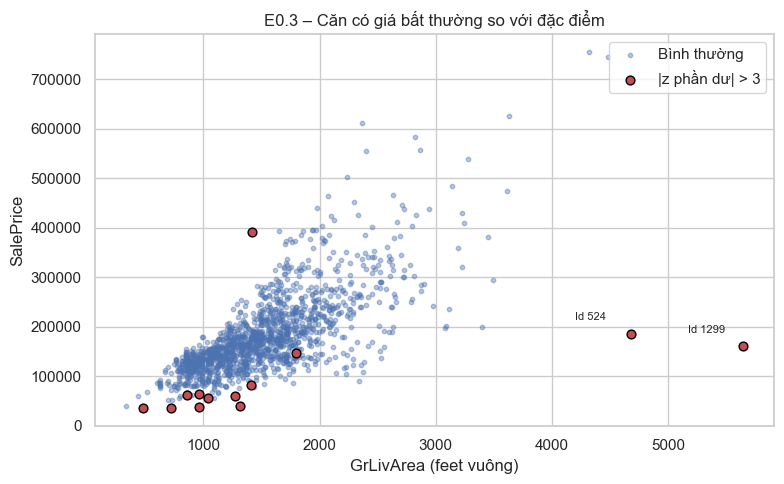

,Id,GrLivArea,OverallQual,SalePrice,z_phan_du
1298,1299,5642,10,160000,-13.09
523,524,4676,10,184750,-8.91
30,31,1317,4,40000,-5.47
632,633,1411,7,82500,-4.88
410,411,1276,5,60000,-4.51
812,813,1044,5,55993,-4.49
495,496,720,4,34900,-4.48
1324,1325,1795,8,147000,-4.09
916,917,480,2,35311,-3.99
462,463,864,5,62383,-3.53


In [8]:
# Ngoại lai theo giá: phần dư của hồi quy tuyến tính trên 10 đặc trưng số quan trọng nhất
top_num10 = [c for c in scores.index if c in num_cols][:10]
lr = LinearRegression().fit(Xa[top_num10], y_log)
resid = y_log - lr.predict(Xa[top_num10])
z = (resid - resid.mean()) / resid.std()
out_idx = z[z.abs() > 3].index
outliers = train.loc[out_idx, ["Id", "GrLivArea", "OverallQual", "SalePrice"]].assign(z_phan_du=z[out_idx].round(2))
outliers = outliers.sort_values("z_phan_du")
outliers.to_csv(FIG / "c1_E0.3_ngoai_lai_theo_gia.csv", index=False)

big_cheap = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]["Id"].tolist()
print("Căn diện tích > 4000 nhưng giá < 300k (Id):", big_cheap)
print("Số căn có |z phần dư| > 3:", len(outliers))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train["GrLivArea"], y, s=10, alpha=0.4, label="Bình thường")
ax.scatter(train.loc[out_idx, "GrLivArea"], y[out_idx], s=40, color="#C44E52",
           edgecolor="black", label="|z phần dư| > 3")
for i in train.index[train["Id"].isin(big_cheap)]:
    ax.annotate(f"Id {train.at[i, 'Id']}", (train.at[i, "GrLivArea"], y[i]),
                textcoords="offset points", xytext=(-40, 10), fontsize=8)
ax.set_xlabel("GrLivArea (feet vuông)"); ax.set_ylabel("SalePrice")
ax.set_title("E0.3 – Căn có giá bất thường so với đặc điểm")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "c1_E0.3_ngoai_lai_theo_gia.png", dpi=150); plt.show()
outliers

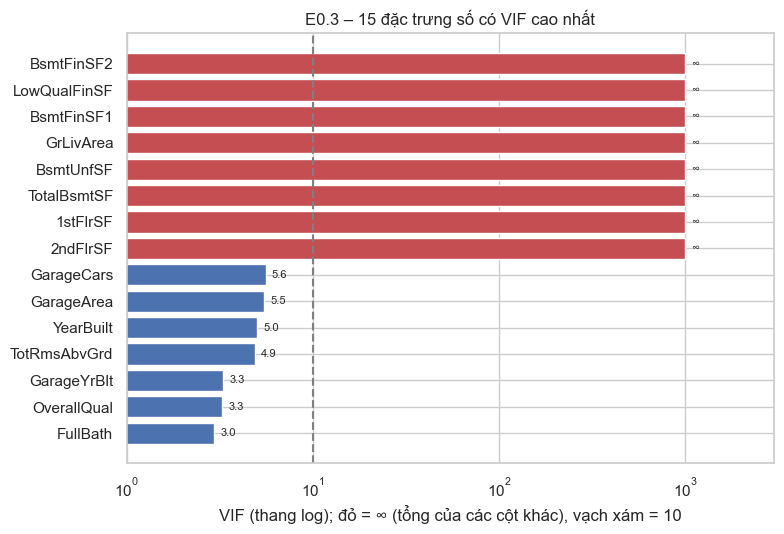

In [9]:
# Đa cộng tuyến: cặp tương quan cao và VIF
pear = Xa[num_cols].corr()
pairs = (pear.where(np.triu(np.ones(pear.shape, dtype=bool), k=1)).stack()
             .rename("tuong_quan").reset_index().rename(columns={"level_0": "dac_trung_1", "level_1": "dac_trung_2"}))
high_corr = pairs[pairs["tuong_quan"].abs() > 0.8].sort_values("tuong_quan", key=abs, ascending=False)
high_corr.to_csv(FIG / "c1_E0.3_cap_tuong_quan_cao.csv", index=False)

def vif_table(df):
    vals = {}
    for c in df.columns:
        others = df.drop(columns=c)
        r2 = LinearRegression().fit(others, df[c]).score(others, df[c])
        vals[c] = np.inf if r2 > 0.9999 else 1 / (1 - r2)
    return pd.Series(vals).sort_values(ascending=False)

num_vif = [c for c in num_cols if Xa[c].std() > 0]
vif = vif_table(Xa[num_vif]).to_frame("VIF")
vif.to_csv(FIG / "c1_E0.3_vif.csv")
print("Cặp |tương quan| > 0.8:"); print(high_corr.round(2).to_string(index=False))
print("\nĐặc trưng VIF = ∞ (là tổng của các cột khác):", vif.index[np.isinf(vif["VIF"])].tolist())
print("Đặc trưng VIF > 10:", vif.index[(vif["VIF"] > 10) & ~np.isinf(vif["VIF"])].tolist())

plot_vif = vif.head(15)["VIF"]
INF_BAR = 1000  # vẽ VIF = ∞ thành thanh dài 1000 và ghi chú "∞"
bars = plot_vif.replace(np.inf, INF_BAR)
colors = ["#C44E52" if np.isinf(v) else ("#DD8452" if v > 10 else "#4C72B0") for v in plot_vif]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(plot_vif.index[::-1], bars[::-1], color=colors[::-1])
for i, v in enumerate(plot_vif[::-1]):
    ax.text(min(v, INF_BAR) * 1.08, i, "∞" if np.isinf(v) else f"{v:.1f}", va="center", fontsize=8)
ax.axvline(10, ls="--", color="gray"); ax.set_xscale("log"); ax.set_xlim(1, INF_BAR * 3)
ax.set_xlabel("VIF (thang log); đỏ = ∞ (tổng của các cột khác), vạch xám = 10")
ax.set_title("E0.3 – 15 đặc trưng số có VIF cao nhất")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.3_vif.png", dpi=150); plt.show()

## Tóm tắt E0.3

In [10]:
summary = f"""E0.3 (C1): {len(iqr_tbl)} đặc trưng số có ngoại lai cực đoan (ngoài 3·IQR); {len(outliers)} căn có giá bất thường (|z phần dư| > 3).
  Căn diện tích > 4000 nhưng giá < 300k: Id {big_cheap} → đề xuất bỏ khi huấn luyện.
  {len(high_corr)} cặp tương quan > 0.8: {'; '.join(f'{a}–{b} ({r:.2f})' for a, b, r in high_corr.head(5).itertuples(index=False))}.
  VIF = ∞ (là tổng các cột khác): {', '.join(vif.index[np.isinf(vif['VIF'])])}."""
log.info("Tóm tắt " + "E0.3" + ":\n" + summary)
(FIG / "c1_E0.3_tom_tat.txt").write_text(summary, encoding="utf-8")

435

## Log lên W&B (minh chứng)

In [11]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.3", "c1-E0.3-Han-ngoai-lai-da-cong-tuyen",
            {"n_features_extreme_outliers": len(iqr_tbl), "n_price_outliers": len(outliers),
             "n_high_corr_pairs": len(high_corr), "n_vif_inf": int(np.isinf(vif["VIF"]).sum()),
             "n_vif_gt_10": int((vif["VIF"] > 10).sum())},
            {"ngoai_lai_theo_gia": outliers, "cap_tuong_quan_cao": high_corr.round(3),
             "vif": vif.replace(np.inf, 1e9).round(2).reset_index(names="dac_trung")},
            ["c1_E0.3_ngoai_lai_theo_gia.png", "c1_E0.3_vif.png"],
            {"iqr_k": 3, "z_threshold": 3, "corr_threshold": 0.8})


## Nhật ký

- 08/11/2026 – Viết phân tích ngoại lai và đa cộng tuyến (E0.3) lần đầu trong notebook `01_eda_Han.ipynb`. Commit `5f6c769`.
- 13/11/2026 – Tách E0.3 ra thành notebook riêng `01_E0.3_ngoai_lai_da_cong_tuyen_Han.ipynb`, thêm ô ghi log, đọc bảng xếp hạng từ E0.2. Chạy lại, số khớp bản 08/11. Commit `dce43dc`.